<a href="https://colab.research.google.com/github/JaviSantosM/Economia3/blob/main/Portafolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Portafolio de Inversión


##Librerías

In [62]:
import yfinance as yf
import pandas as pd
import numpy as np
import datetime as dt

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)


import statsmodels.formula.api as smf
import scipy.stats as stats
from scipy import stats
import re

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Datos

In [84]:

nombres_empresas = {
     "005930.KS": "Samsung",
    "NVDA": "NVIDIA",
    "DIS": "Disney",
    "AMZN": "Amazon",
    "ENR.DE": "Siemens",
    "WOOF": "Petco",
    "MCD": "McDonald's",
    "F": "Ford",
    "MA": "Mastercard",
    "FUNO11.MX": "Fibra Uno"
}


#df_usd = df_usd.rename(columns=nombres_empresas)
retorno=retorno.rename(columns=nombres_empresas)

#df_usd.head()
retorno.head()

,Samsung,Amazon,Disney,Siemens,Ford,Fibra Uno,Mastercard,McDonald's,NVIDIA,Petco
Date,,,,,,,,,,
2024-01-03,-0.043079,-0.009738,0.010363,-0.072171,-0.037007,-0.013824,-0.007395,-0.008922,-0.012436,-0.075949
2024-01-04,-0.006646,-0.026268,-0.011893,0.023409,-0.002562,-0.021835,0.002388,-0.009002,0.009018,-0.010274
2024-01-05,-0.001312,0.004634,0.003755,0.012780,0.014555,0.017875,-0.000834,-0.009426,0.022897,0.027682
2024-01-08,-0.002735,0.026577,0.007151,0.051999,0.010127,0.015634,0.007689,0.010070,0.064281,-0.020202
2024-01-09,-0.022540,0.015225,-0.020535,-0.008624,-0.010860,-0.005495,0.001469,-0.003529,0.016975,0.010309


In [73]:
#Guardar
df_usd.to_csv("/content/drive/MyDrive/Colab Notebooks/portafolio.csv")
retorno.to_csv("/content/drive/MyDrive/Colab Notebooks/retornoportafolio.csv")

In [74]:
#Cargar
df_usd=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/portafolio.csv",index_col=0, parse_dates=True)
retorno = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/retornoportafolio.csv",index_col=0, parse_dates=True)

###Borrador de Limpieza de datos

In [ ]:
#Descargar
df_FU=yf.download("FUNO11.MX",start= "2024-01-01", end="2026-01-01")
df_FU.head()


/tmp/ipykernel_2024/588514958.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_FU=yf.download("FUNO11.MX",start= "2024-01-01", end="2026-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,FUNO11.MX,FUNO11.MX,FUNO11.MX,FUNO11.MX,FUNO11.MX
Date,,,,,
2024-01-02,23.949108,24.366229,23.720871,24.098643,3137131
2024-01-03,23.697258,24.051417,23.531982,23.949105,3369776
2024-01-04,23.169952,23.673647,23.162082,23.673647,2480369
2024-01-05,23.579203,23.705128,23.169952,23.169952,3889594
2024-01-08,23.768089,23.956975,23.579203,23.610684,2597223
...,...,...,...,...,...
2025-12-24,25.445713,25.633090,25.192754,25.445713,742000
2025-12-26,25.286444,25.539402,25.211493,25.417607,1690690


In [ ]:
df_FU.colums=["Date","Close","High","Low","Open","Volume"]
df_FU["Close"]=df_FU.Close.astype("float")
df_FU = df_FU[['Close']]
df_FU.index.name = None
df_FU.columns.name = "Date"
df_FU.head(10)
df_FU.head()

/tmp/ipykernel_2024/3247446897.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df_FU.colums=["Date","Close","High","Low","Open","Volume"]


Price,Close
Ticker,FUNO11.MX
2024-01-02,23.949108
2024-01-03,23.697258
2024-01-04,23.169952
2024-01-05,23.579203
2024-01-08,23.768089


In [ ]:
df_FU.columns = df_FU.columns.droplevel(1)
df_FU.head()

Price,Close
2024-01-02,23.949108
2024-01-03,23.697258
2024-01-04,23.169952
2024-01-05,23.579203
2024-01-08,23.768089


##Limpieza de Datos

In [3]:
import yfinance as yf

tickers = ["005930.KS", "NVDA", "DIS", "AMZN", "ENR.DE", "WOOF", "MCD", "F", "MA", "FUNO11.MX"]
df_portafolio = yf.download(tickers, start="2024-01-01", end="2026-01-01")['Close']
df_portafolio.index.name = "Date"
df_portafolio.columns.name = None

df_portafolio.head()


/tmp/ipykernel_8184/2055040882.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_portafolio = yf.download(tickers, start="2024-01-01", end="2026-01-01")['Close']
[*********************100%***********************]  10 of 10 completed


,005930.KS,AMZN,DIS,ENR.DE,F,FUNO11.MX,MA,MCD,NVDA,WOOF
Date,,,,,,,,,,
2024-01-02,76030.101562,149.929993,88.235710,11.834533,10.226173,23.949104,414.403473,277.953217,48.028790,3.16
2024-01-03,73546.710938,148.470001,89.150070,11.077760,9.847738,23.697262,411.338806,275.473450,47.431522,2.92
2024-01-04,73164.664062,144.570007,88.089790,11.351592,9.822508,23.169952,412.321045,272.993713,47.859283,2.89
2024-01-05,73164.664062,145.240005,88.420525,11.476061,9.965474,23.579206,411.977325,270.420441,48.955097,2.97
2024-01-08,73069.148438,149.100006,89.052795,12.078492,10.066390,23.768093,415.145172,273.143433,52.101990,2.91


In [4]:
# Pasar todo a USD
divisas = ["MXN=X", "KRW=X", "EURUSD=X"]
df_divisas = yf.download(divisas, start="2024-01-01", end="2026-01-01")['Close']

df_usd = df_portafolio.copy()

df_usd["FUNO11.MX"] = df_usd["FUNO11.MX"] / df_divisas["MXN=X"]
df_usd["005930.KS"] = df_usd["005930.KS"] / df_divisas["KRW=X"]
df_usd["ENR.DE"] = df_usd["ENR.DE"] * df_divisas["EURUSD=X"]

#Rellenar valores nulos generados por los diferentes días festivos entre países
df_usd = df_usd.ffill()
df_usd.head()

/tmp/ipykernel_8184/4102219092.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_divisas = yf.download(divisas, start="2024-01-01", end="2026-01-01")['Close']
[*********************100%***********************]  3 of 3 completed


,005930.KS,AMZN,DIS,ENR.DE,F,FUNO11.MX,MA,MCD,NVDA,WOOF
Date,,,,,,,,,,
2024-01-02,58.776767,149.929993,88.235710,13.063840,10.226173,1.411885,414.403473,277.953217,48.028790,3.16
2024-01-03,56.244713,148.470001,89.150070,12.121015,9.847738,1.392368,411.338806,275.473450,47.431522,2.92
2024-01-04,55.870933,144.570007,88.089790,12.404756,9.822508,1.361965,412.321045,272.993713,47.859283,2.89
2024-01-05,55.797647,145.240005,88.420525,12.563288,9.965474,1.386311,411.977325,270.420441,48.955097,2.97
2024-01-08,55.645022,149.100006,89.052795,13.216571,10.066390,1.407984,415.145172,273.143433,52.101990,2.91


##Activos

In [75]:
#Imaginar que le damos 100 USD a cada activo en la primera fecha
df_base100 = (df_usd / df_usd.iloc[0]) * 100

fig_base100 = go.Figure()

for col in df_base100.columns:
    fig_base100.add_trace(go.Scatter(
        x=df_base100.index,
        y=df_base100[col],
        mode='lines',
        name=col
    ))

fig_base100.update_layout(
    title="Rendimiento Acumulado Histórico de los Activos (Base 100 USD)",
    xaxis_title="Fecha",
    yaxis_title="Valor Normalizado (Inicio = 100)",
    template="plotly_white",
    height=600,
    legend_title="Activo"
)

fig_base100.show()

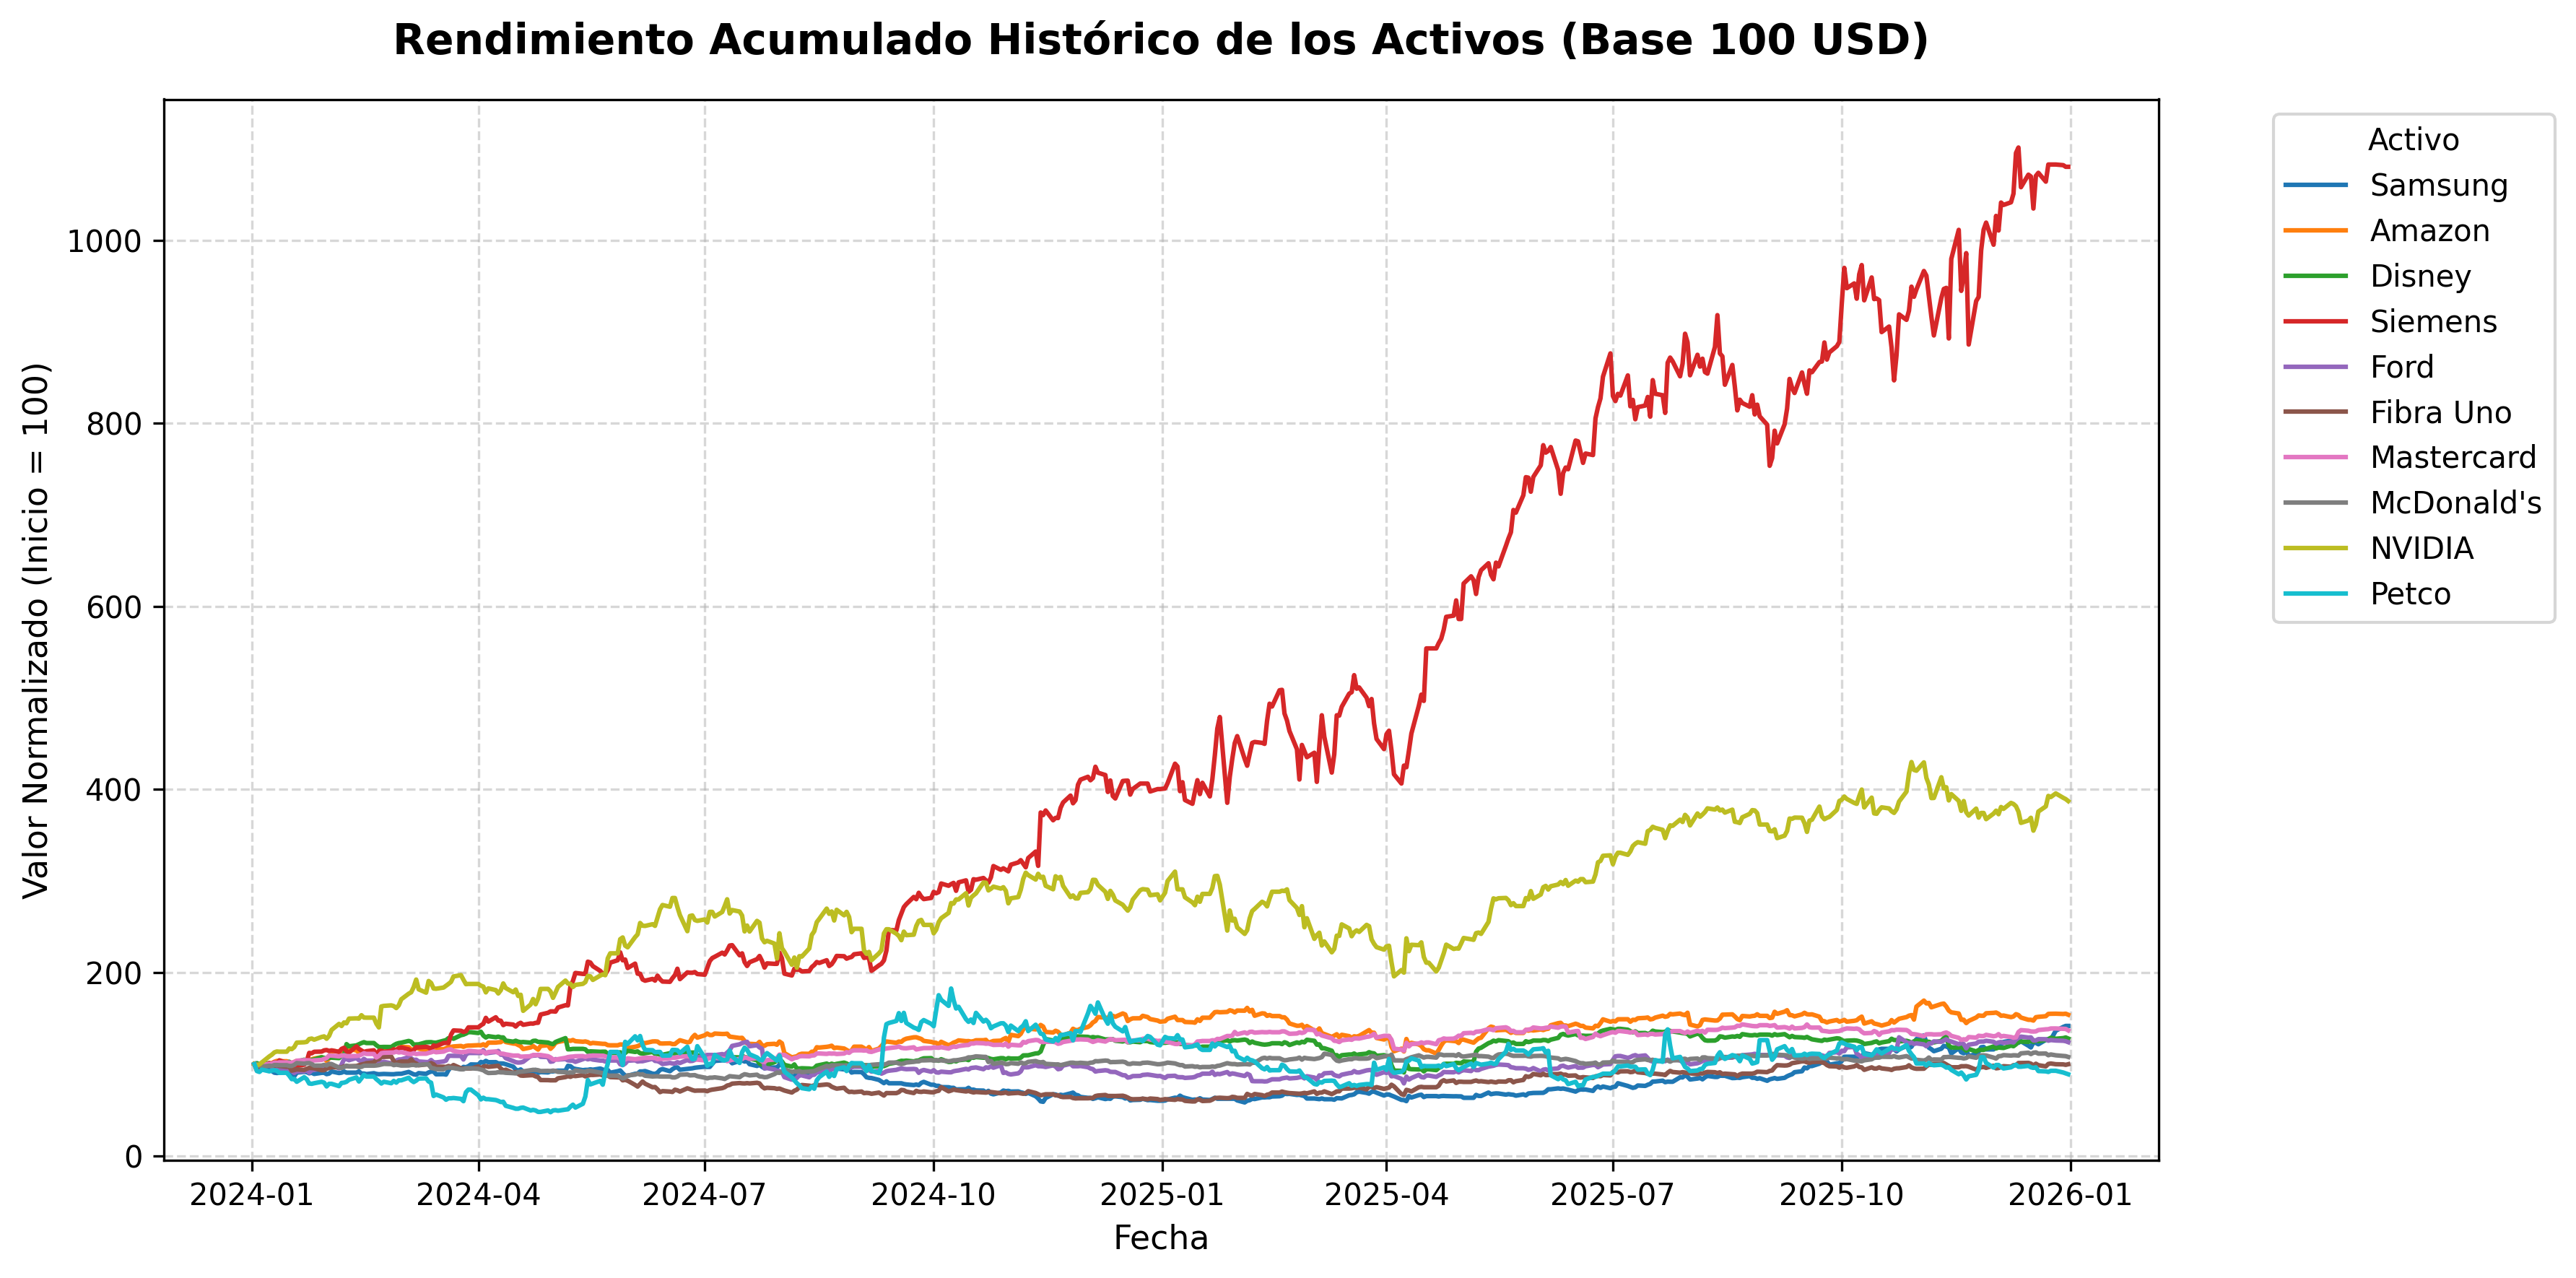

In [79]:
# 1. Calcular el rendimiento acumulado Base 100
df_base100 = (df_usd / df_usd.iloc[0]) * 100

# 2. Crear la figura estática
plt.figure(figsize=(12, 6), dpi=300) # dpi=300 garantiza calidad para la presentación[cite: 1]

for col in df_base100.columns:
    plt.plot(df_base100.index, df_base100[col], label=col, linewidth=1.5)

# 3. Personalizar títulos y ejes
plt.title("Rendimiento Acumulado Histórico de los Activos (Base 100 USD)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Fecha", fontsize=11)
plt.ylabel("Valor Normalizado (Inicio = 100)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Activo", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)

plt.tight_layout()

# 4. Guardar la imagen localmente en alta resolución
plt.savefig("/content/drive/MyDrive/Colab Notebooks/rendimiento_base100.png", dpi=300, bbox_inches='tight')

# 5. Mostrar la imagen estática en el cuaderno[cite: 1]
plt.show()

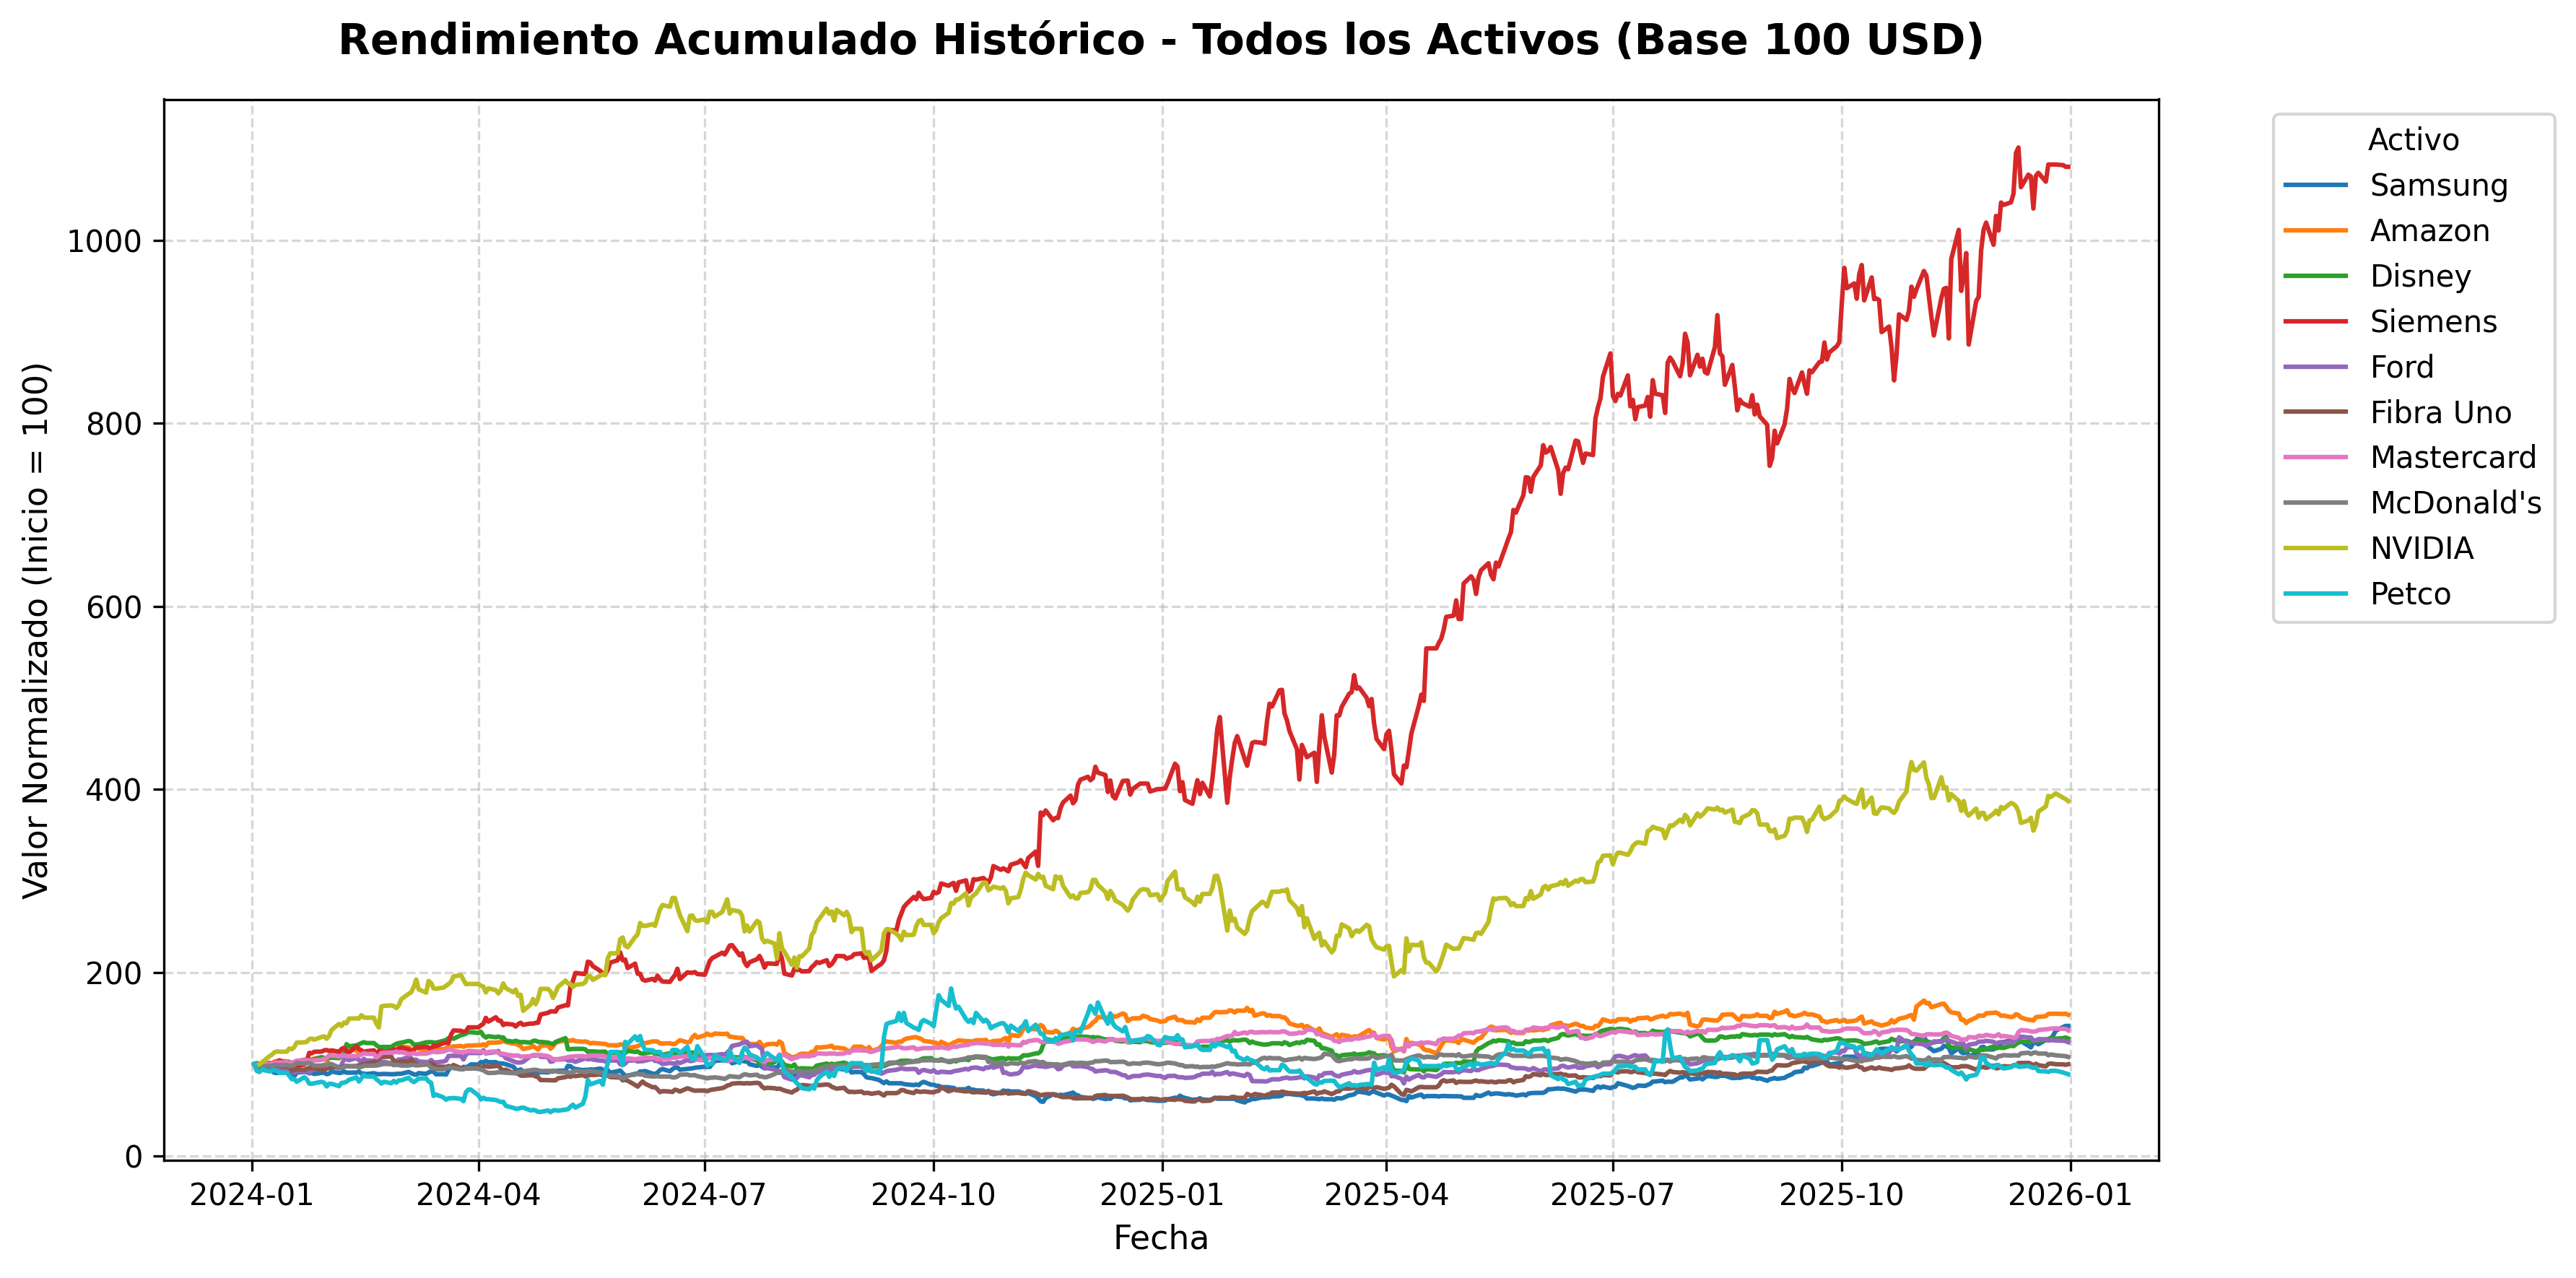

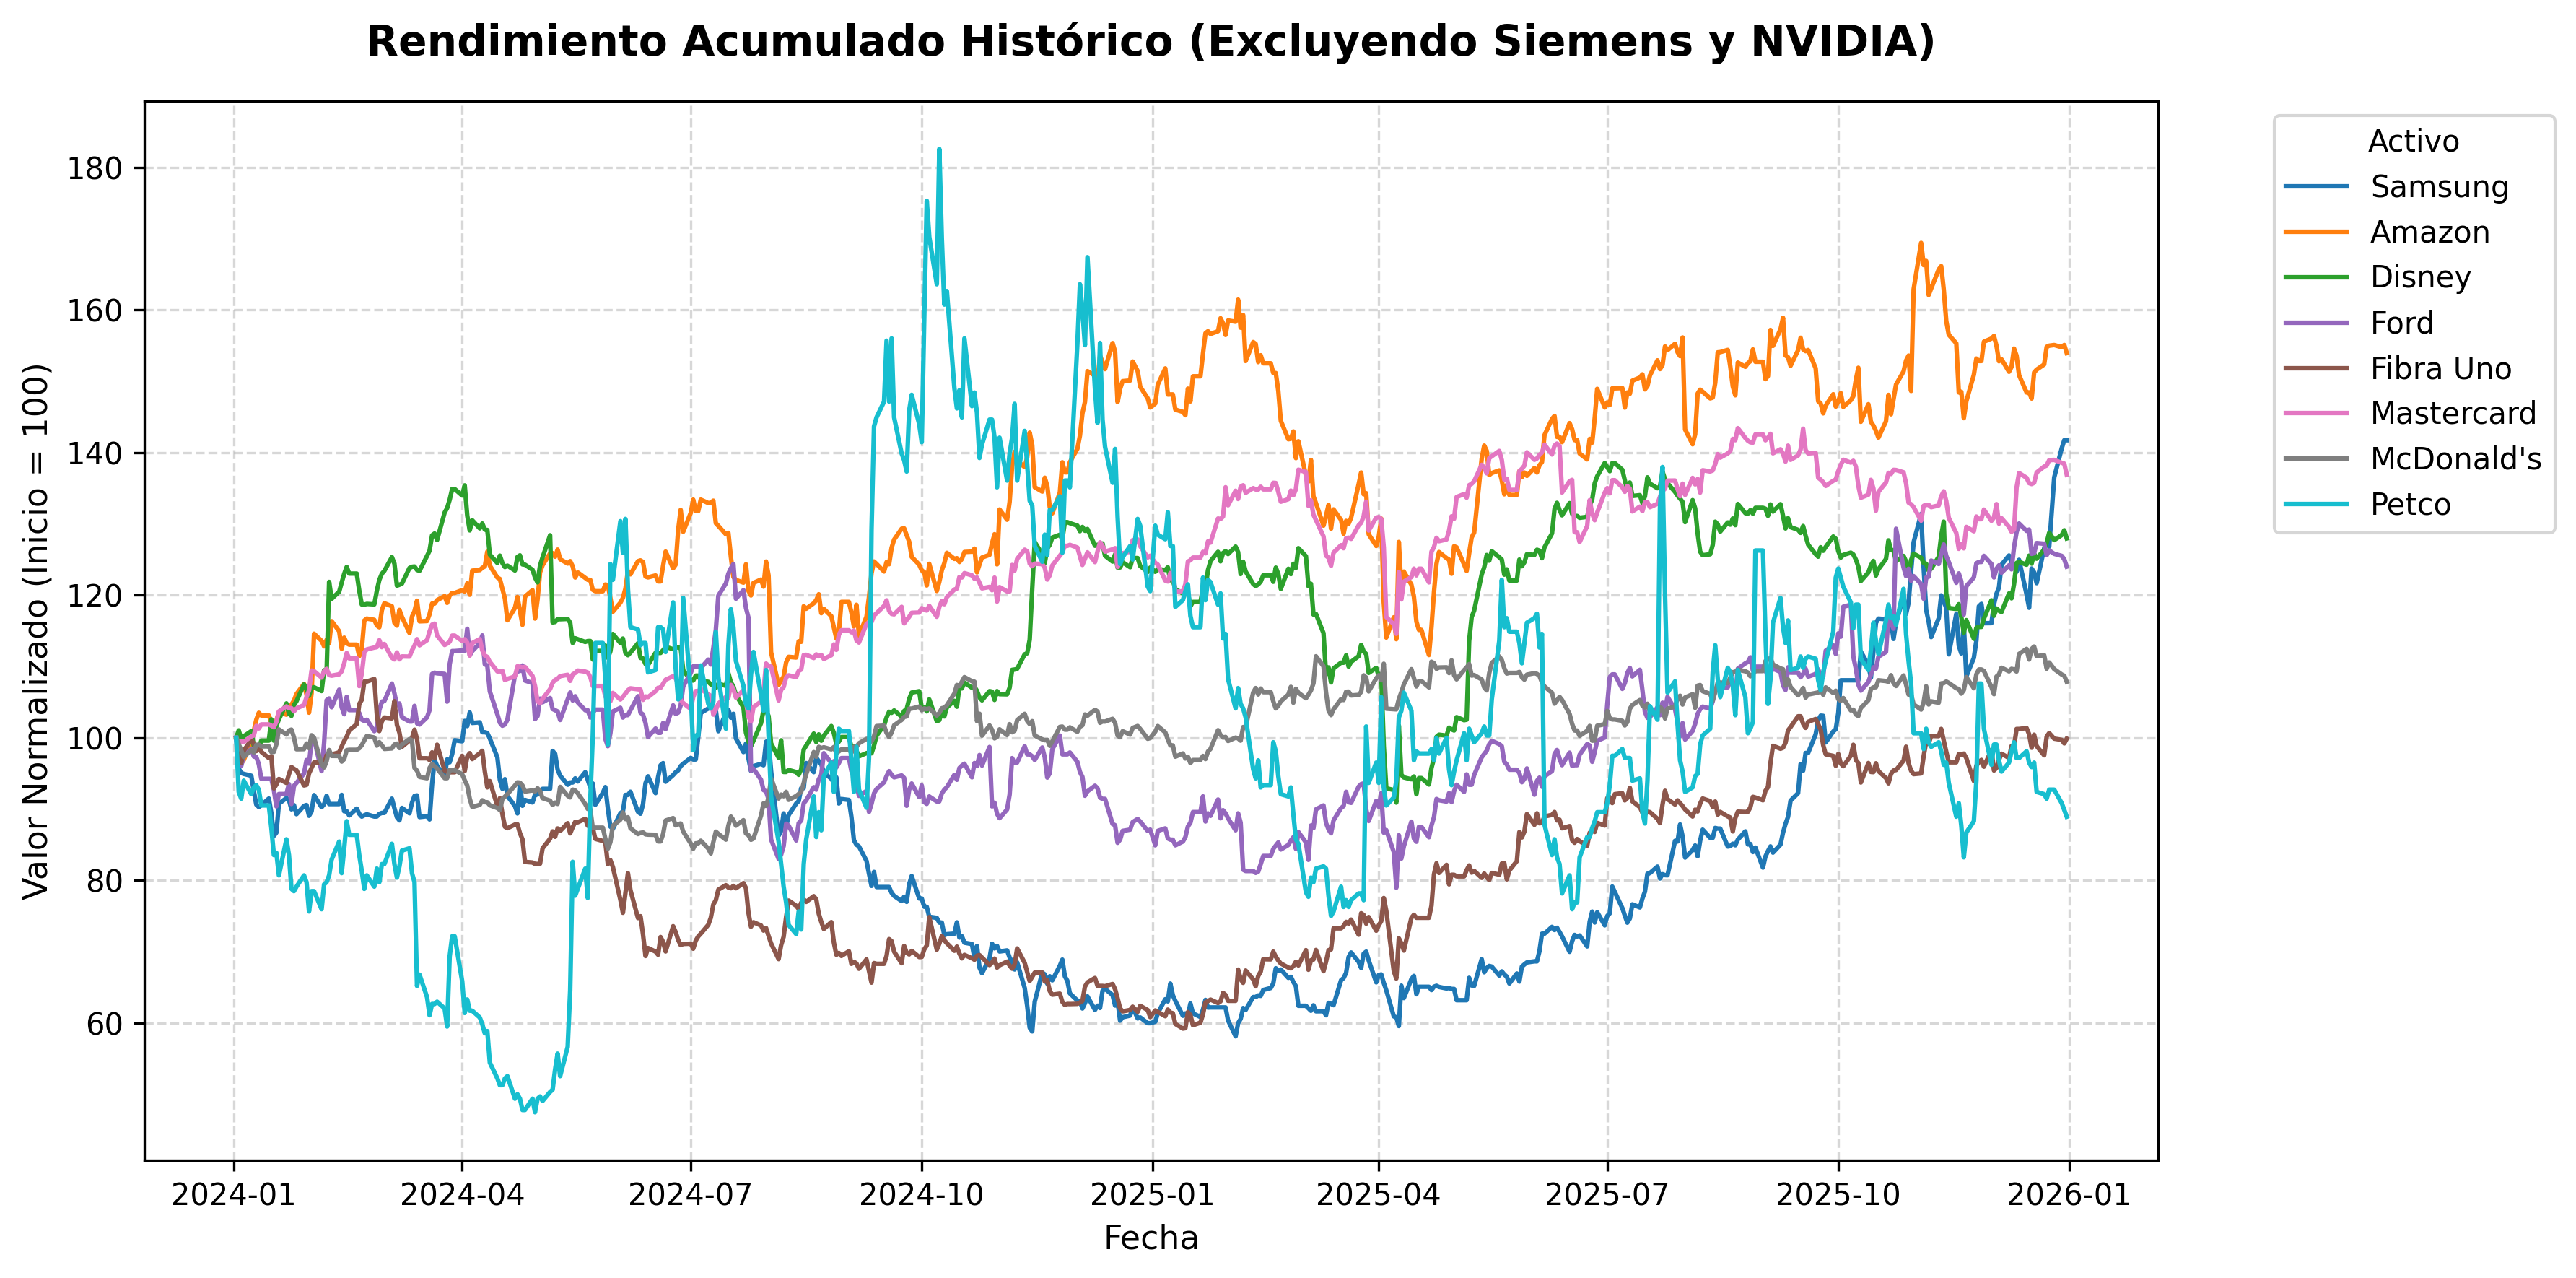

In [81]:
# 1. Definir una paleta de colores fija para cada columna
# Asignamos un color específico a cada activo presente en el DataFrame
colores = plt.cm.tab10.colors  # Paleta estándar de 10 colores distintivos
color_map = {col: colores[i % len(colores)] for i, col in enumerate(df_usd.columns)}

# 2. Calcular Base 100[cite: 1]
df_base100 = (df_usd / df_usd.iloc[0]) * 100

# ==========================================
# GRAFICA 1: Todos los activos
# ==========================================
plt.figure(figsize=(12, 6), dpi=300)

for col in df_base100.columns:
    plt.plot(df_base100.index, df_base100[col], label=col, color=color_map[col], linewidth=1.5)

plt.title("Rendimiento Acumulado Histórico - Todos los Activos (Base 100 USD)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Fecha", fontsize=11)
plt.ylabel("Valor Normalizado (Inicio = 100)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Activo", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()

# Guardar primera imagen
plt.savefig("/content/drive/MyDrive/Colab Notebooks/rendimiento_base100_todos.png", dpi=300, bbox_inches='tight')
plt.show()


# ==========================================
# GRAFICA 2: Excluyendo Siemens y NVIDIA (Conservando colores)
# ==========================================
columnas_excluidas = ["Siemens", "NVIDIA"]

plt.figure(figsize=(12, 6), dpi=300)

for col in df_base100.columns:
    if col not in columnas_excluidas:
        # Se dibuja la línea manteniendo color_map[col]
        plt.plot(df_base100.index, df_base100[col], label=col, color=color_map[col], linewidth=1.5)

plt.title("Rendimiento Acumulado Histórico (Excluyendo Siemens y NVIDIA)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Fecha", fontsize=11)
plt.ylabel("Valor Normalizado (Inicio = 100)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Activo", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()

# Guardar segunda imagen
plt.savefig("/content/drive/MyDrive/Colab Notebooks/rendimiento_base100_filtrado.png", dpi=300, bbox_inches='tight')
plt.show()

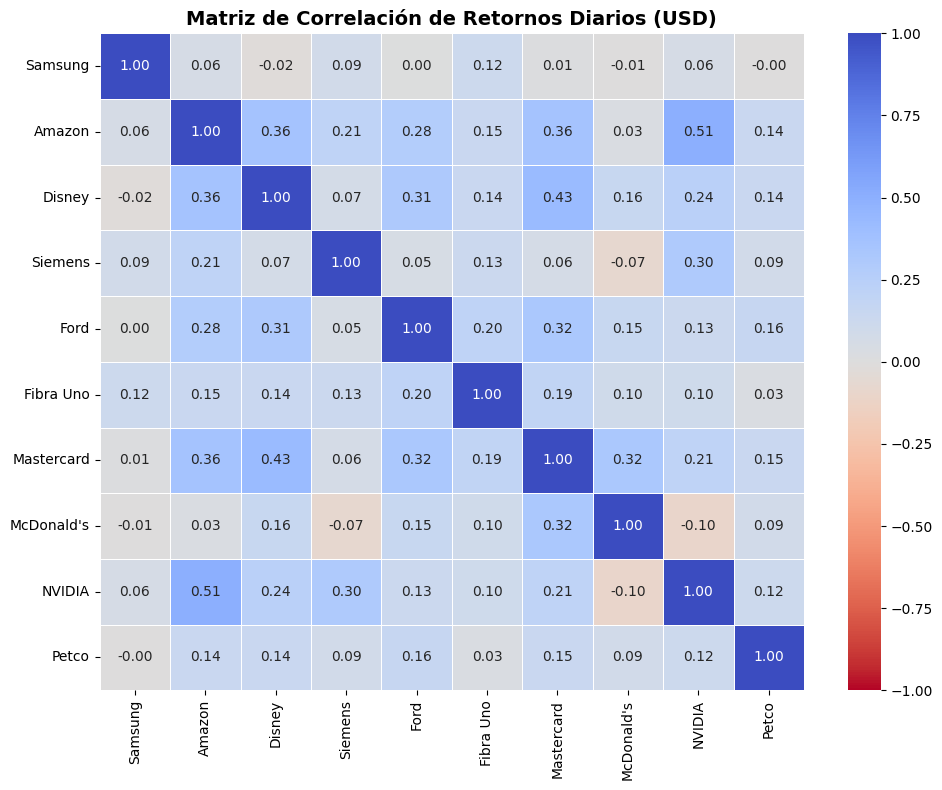

In [87]:

matriz_corr = retorno.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm_r",
    vmin=-1, vmax=1,
    linewidths=0.5
)

plt.title("Matriz de Correlación de Retornos Diarios (USD)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Colab Notebooks/heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

In [77]:
# Definición de activos y pesos (10% cada uno)
activos = list(df_usd.columns)
n_activos = len(activos)
pesos = [1/n_activos] * n_activos  # 0.10 para cada uno
monto_total = 1_000_000

# Valores en USD asignados
valores_usd = [monto_total * p for p in pesos]

# Crear gráfico Donut / Pastel
fig_pie = go.Figure(data=[go.Pie(
    labels=activos,
    values=valores_usd,
    hole=0.4, # Crea el estilo 'donut' profesional
    textinfo='label+percent',
    hovertemplate="<b>%{label}</b><br>Asignación: %{percent}<br>Monto: $%{value:,.0f} USD<extra></extra>"
)])

fig_pie.update_layout(
    title_text="<b>Estructura de Asignación del Portafolio ($1,000,000 USD)</b>",
    annotations=[dict(text='10 Activos<br>10% c/u', x=0.5, y=0.5, font_size=14, showarrow=False)],
    template="plotly_white",
    height=500
)

fig_pie.show()

##Portafolio

##Un solo activo

In [29]:
df_usd.tail()

,005930.KS,AMZN,DIS,ENR.DE,F,FUNO11.MX,MA,MCD,NVDA,WOOF
Date,,,,,,,,,,
2025-12-24,74.534963,232.380005,113.609474,141.470569,12.912485,1.421208,575.748901,307.306091,188.169678,2.93
2025-12-26,80.237737,232.520004,112.696465,141.470569,12.864161,1.410124,575.897949,304.707001,190.085205,2.93
2025-12-29,82.647144,232.070007,113.321678,141.376345,12.835165,1.407695,574.208862,302.598328,187.780594,2.87
2025-12-30,83.306407,232.529999,113.917114,141.143563,12.786839,1.400723,573.731873,302.107971,187.102173,2.84
2025-12-31,83.306407,230.820007,112.904869,141.143563,12.680524,1.410107,567.233704,299.754120,186.064606,2.81


In [28]:
retorno=df_usd.pct_change().dropna().copy()
retorno.tail()

,005930.KS,AMZN,DIS,ENR.DE,F,FUNO11.MX,MA,MCD,NVDA,WOOF
Date,,,,,,,,,,
2025-12-24,-0.004821,0.001034,0.011129,0.000000,0.005267,0.004820,0.005379,0.008011,-0.003171,0.013841
2025-12-26,0.076511,0.000602,-0.008036,0.000000,-0.003742,-0.007799,0.000259,-0.008458,0.010180,0.000000
2025-12-29,0.030028,-0.001935,0.005548,-0.000666,-0.002254,-0.001723,-0.002933,-0.006920,-0.012124,-0.020478
2025-12-30,0.007977,0.001982,0.005254,-0.001647,-0.003765,-0.004953,-0.000831,-0.001620,-0.003613,-0.010453
2025-12-31,0.000000,-0.007354,-0.008886,0.000000,-0.008314,0.006699,-0.011326,-0.007791,-0.005545,-0.010563


In [26]:
activo="NVIDIA"
SO=df_usd[activo].iloc[-1]
mu_log=retorno[activo].mean()*252
sigma=retorno[activo].std()*np.sqrt(252)
mu=mu_log+0.5*sigma**2

In [27]:
print(f"\nPrecio actual:${SO:2f}")
print(f"\n drift analizado:{mu:2f}")
print(f"\n volatilidad analizada:{sigma:2f}")


Precio actual:$186.064606

 drift analizado:0.911525

 volatilidad analizada:0.502473


In [32]:
np.random.seed(42)
Z=np.random.normal(0,1,1_000_000)
# Estadísticas (deberían ser ≈ 0 y 1)
print("=== Normal estándar (100K muestras) ===")
print(f"  Media:    {Z.mean():.4f} (teórico: 0)")
print(f"  Std:      {Z.std():.4f} (teórico: 1)")
print(f"  Skewness: {stats.skew(Z):.4f} (teórico: 0)")
print(f"  Curtosis: {stats.kurtosis(Z):.4f} (teórico: 0)")

=== Normal estándar (100K muestras) ===
  Media:    -0.0016 (teórico: 0)
  Std:      1.0002 (teórico: 1)
  Skewness: -0.0014 (teórico: 0)
  Curtosis: -0.0056 (teórico: 0)


In [34]:
# Simular una trayectoria de GBM paso a paso
np.random.seed(42)
T = 1.0       # 1 año
dt = 1/252    # Paso diario
n_pasos = int(T / dt)

# Generar incrementos aleatorios
Z = np.random.normal(0, 1, n_pasos)

# Simular precio paso a paso
precios_sim = np.zeros(n_pasos + 1)
precios_sim[0] = SO

for t in range(n_pasos):
    precios_sim[t+1] = precios_sim[t] * np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z[t])

# Visualizar
fechas_sim = pd.bdate_range(start=df_usd[activo].index[-1], periods=n_pasos+1)

fig = go.Figure()
fig.add_trace(go.Scatter(x=df_usd[activo].index, y=df_usd[activo], name="Histórico",
                         line=dict(color="steelblue", width=1.5)))
fig.add_trace(go.Scatter(x=fechas_sim, y=precios_sim, name="GBM simulado",
                         line=dict(color="red", width=1.5, dash="dash")))

fig.update_layout(template="plotly_white",
                  title=f"{activo} — Una trayectoria GBM (μ={mu:.2%}, σ={sigma:.2%})",
                  yaxis_title="Precio ($)", xaxis_title="Fecha")
fig.show()

print(f"📊 Precio final simulado: ${precios_sim[-1]:.2f} (cambio: {precios_sim[-1]/SO-1:+.2%})")
print(f"  Esta es UNA sola realización posible del futuro")
print(f"  Monte Carlo = generar MILES de estas trayectorias")

📊 Precio final simulado: $395.97 (cambio: +112.82%)
  Esta es UNA sola realización posible del futuro
  Monte Carlo = generar MILES de estas trayectorias


In [35]:
# Simulación VECTORIZADA: 10,000 trayectorias simultáneas (eficiente)
np.random.seed(42)
n_sims = 10_000
T = 1.0
dt = 1/252
n_pasos = int(T / dt)

# Generar TODOS los incrementos de una vez: (n_pasos × n_sims)
Z_matrix = np.random.normal(0, 1, (n_pasos, n_sims))

# Retornos log diarios simulados
log_returns = (mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z_matrix

# Precios: S₀ × exp(suma acumulada de retornos)
log_prices = np.vstack([np.zeros(n_sims), np.cumsum(log_returns, axis=0)])
price_matrix = SO * np.exp(log_prices)

print(f"Matriz de precios: {price_matrix.shape} (pasos × simulaciones)")
print(f"Precio inicial: ${SO:.2f}")
print(f"Precio final — media: ${price_matrix[-1].mean():.2f}")
print(f"Precio final — mediana: ${np.median(price_matrix[-1]):.2f}")
print(f"Precio final — min: ${price_matrix[-1].min():.2f}")
print(f"Precio final — max: ${price_matrix[-1].max():.2f}")

# Verificar: E[S_T] ≈ S₀ × exp(μT)
precio_esperado = SO * np.exp(mu * T)
print(f"\nE[S_T] teórico: ${precio_esperado:.2f}")
print(f"E[S_T] simulado: ${price_matrix[-1].mean():.2f}")
print(f"Error: {abs(price_matrix[-1].mean()/precio_esperado - 1):.4%}")

Matriz de precios: (253, 10000) (pasos × simulaciones)
Precio inicial: $186.06
Precio final — media: $460.77
Precio final — mediana: $407.41
Precio final — min: $71.75
Precio final — max: $2631.76

E[S_T] teórico: $462.95
E[S_T] simulado: $460.77
Error: 0.4707%


In [36]:
# Visualizar múltiples trayectorias
fig = go.Figure()

# Mostrar 100 trayectorias (de las 10K)
for i in range(100):
    fig.add_trace(go.Scatter(x=list(range(n_pasos+1)), y=price_matrix[:, i],
                             mode="lines", line=dict(width=0.3, color="steelblue"),
                             opacity=0.2, showlegend=False))

# Media y percentiles
media = price_matrix.mean(axis=1)
p5 = np.percentile(price_matrix, 5, axis=1)
p25 = np.percentile(price_matrix, 25, axis=1)
p75 = np.percentile(price_matrix, 75, axis=1)
p95 = np.percentile(price_matrix, 95, axis=1)

fig.add_trace(go.Scatter(x=list(range(n_pasos+1)), y=media, name="Media",
                         line=dict(color="red", width=2)))
fig.add_trace(go.Scatter(x=list(range(n_pasos+1)), y=p5, name="P5",
                         line=dict(color="orange", width=1, dash="dash")))
fig.add_trace(go.Scatter(x=list(range(n_pasos+1)), y=p95, name="P95",
                         line=dict(color="orange", width=1, dash="dash")))

fig.add_hline(y=SO, line_dash="dot", line_color="gray", opacity=0.5)

fig.update_layout(template="plotly_white", height=550,
                  title=f"10,000 trayectorias GBM — {activo} (100 mostradas)",
                  xaxis_title="Días", yaxis_title="Precio ($)")
fig.show()

print("📊 Cada línea azul tenue es un 'futuro posible'")
print("  • Línea roja = media de todas las simulaciones")
print("  • Naranja punteada = percentiles 5% y 95% (intervalo del 90%)")
print("  • El 'abanico' se abre con el tiempo → incertidumbre CRECE")

📊 Cada línea azul tenue es un 'futuro posible'
  • Línea roja = media de todas las simulaciones
  • Naranja punteada = percentiles 5% y 95% (intervalo del 90%)
  • El 'abanico' se abre con el tiempo → incertidumbre CRECE


In [37]:
# Comparar distribución simulada vs real
ret_real = ret_log[activo].dropna()
ret_simulado = np.diff(np.log(price_matrix[:, 0]))  # Retornos de 1 simulación

# Retornos finales de todas las simulaciones
ret_finales = np.log(price_matrix[-1] / SO)

fig = make_subplots(rows=1, cols=2,
    subplot_titles=["Retornos diarios: Real vs Simulado (1 tray.)",
                    "Retorno anual: Distribución de 10K simulaciones"])

fig.add_trace(go.Histogram(x=ret_real*100, nbinsx=80, name="Real",
                           marker_color="steelblue", opacity=0.6), row=1, col=1)
fig.add_trace(go.Histogram(x=ret_simulado*100, nbinsx=80, name="Simulado",
                           marker_color="red", opacity=0.4), row=1, col=1)

fig.add_trace(go.Histogram(x=ret_finales*100, nbinsx=80, name="Ret. anual sim.",
                           marker_color="steelblue", opacity=0.7, showlegend=False), row=1, col=2)
fig.add_vline(x=mu*100, line_dash="dash", line_color="red", row=1, col=2,
              annotation_text=f"μ={mu:.1%}", annotation_position="top right")
fig.add_vline(x=0, line_dash="dash", line_color="gray", opacity=0.3, row=1, col=2)

fig.update_layout(template="plotly_white", height=400, barmode="overlay",
                  title="Validación del GBM")
fig.show()

# Comparar momentos
print("=== Comparación de momentos (retornos diarios) ===")
print(f"{'':>15} {'Real':>10} {'Simulado':>10}")
print(f"{'Media (%)':>15} {ret_real.mean()*100:>10.4f} {ret_simulado.mean()*100:>10.4f}")
print(f"{'Std (%)':>15} {ret_real.std()*100:>10.4f} {ret_simulado.std()*100:>10.4f}")
print(f"{'Skewness':>15} {ret_real.skew():>10.4f} {stats.skew(ret_simulado):>10.4f}")
print(f"{'Exc. Curtosis':>15} {ret_real.kurtosis():>10.4f} {stats.kurtosis(ret_simulado):>10.4f}")

print("\n📊 El GBM replica bien la media y std, pero NO las colas pesadas (curtosis)")
print("  → Para modelos más realistas: saltos (Merton), vol. estocástica (Heston)")

=== Comparación de momentos (retornos diarios) ===
                      Real   Simulado
      Media (%)     0.2614     0.6561
        Std (%)     3.1572     3.0356
       Skewness    -0.1448     0.0962
  Exc. Curtosis     5.1061     0.0552

📊 El GBM replica bien la media y std, pero NO las colas pesadas (curtosis)
  → Para modelos más realistas: saltos (Merton), vol. estocástica (Heston)


In [39]:
# Cono de probabilidad detallado
dias = np.arange(n_pasos + 1)
fechas_futuro = pd.bdate_range(start=df_usd[activo].index[-1], periods=n_pasos+1)

# Percentiles
percentiles = {
    "P1": np.percentile(price_matrix, 1, axis=1),
    "P5": np.percentile(price_matrix, 5, axis=1),
    "P10": np.percentile(price_matrix, 10, axis=1),
    "P25": np.percentile(price_matrix, 25, axis=1),
    "P50": np.percentile(price_matrix, 50, axis=1),
    "P75": np.percentile(price_matrix, 75, axis=1),
    "P90": np.percentile(price_matrix, 90, axis=1),
    "P95": np.percentile(price_matrix, 95, axis=1),
    "P99": np.percentile(price_matrix, 99, axis=1),
}

fig = go.Figure()

# Bandas de confianza (más oscuro = más confianza)
fig.add_trace(go.Scatter(x=fechas_futuro, y=percentiles["P99"], line=dict(width=0),
                         showlegend=False))
fig.add_trace(go.Scatter(x=fechas_futuro, y=percentiles["P1"], fill="tonexty",
                         fillcolor="rgba(70,130,180,0.08)", line=dict(width=0),
                         name="98% IC"))

fig.add_trace(go.Scatter(x=fechas_futuro, y=percentiles["P95"], line=dict(width=0),
                         showlegend=False))
fig.add_trace(go.Scatter(x=fechas_futuro, y=percentiles["P5"], fill="tonexty",
                         fillcolor="rgba(70,130,180,0.12)", line=dict(width=0),
                         name="90% IC"))

fig.add_trace(go.Scatter(x=fechas_futuro, y=percentiles["P75"], line=dict(width=0),
                         showlegend=False))
fig.add_trace(go.Scatter(x=fechas_futuro, y=percentiles["P25"], fill="tonexty",
                         fillcolor="rgba(70,130,180,0.2)", line=dict(width=0),
                         name="50% IC (IQR)"))

# Mediana y media
fig.add_trace(go.Scatter(x=fechas_futuro, y=percentiles["P50"], name="Mediana",
                         line=dict(color="red", width=2)))
fig.add_trace(go.Scatter(x=fechas_futuro, y=price_matrix.mean(axis=1), name="Media",
                         line=dict(color="darkred", width=1.5, dash="dash")))

# Histórico
fig.add_trace(go.Scatter(x=df_usd[activo].index[-252:], y=df_usd[activo].iloc[-252:],
                         name="Histórico", line=dict(color="steelblue", width=1.5)))

fig.add_hline(y=SO, line_dash="dot", line_color="gray", opacity=0.5,
              annotation_text=f"S₀=${SO:.2f}", annotation_position="bottom right")

fig.update_layout(template="plotly_white", height=550,
                  title=f"{activo} — Cono de probabilidad a 1 año ({n_sims:,} simulaciones)",
                  yaxis_title="Precio ($)", xaxis_title="Fecha")
fig.show()

# Estadísticas al final del horizonte
print(f"\n📊 Proyección a 1 año desde ${SO:.2f}:")
for p_name, p_val in [("P1", 1), ("P5", 5), ("P25", 25), ("P50 (mediana)", 50),
                       ("P75", 75), ("P95", 95), ("P99", 99)]:
    val = np.percentile(price_matrix[-1], p_val)  # Solo el último día
    cambio = val / SO - 1
    print(f"  {p_name:>15}: ${val:.2f} ({cambio:+.1%})")


📊 Proyección a 1 año desde $186.06:
               P1: $125.29 (-32.7%)
               P5: $178.60 (-4.0%)
              P25: $289.90 (+55.8%)
    P50 (mediana): $407.41 (+119.0%)
              P75: $570.85 (+206.8%)
              P95: $924.80 (+397.0%)
              P99: $1287.54 (+592.0%)


In [40]:
# VaR a diferentes horizontes
inversion = 1_000_000
horizontes = [1, 5, 10, 21, 63, 126, 252]  # días

print(f"=== VaR Monte Carlo a múltiples horizontes — {activo} ===")
print(f"Inversión: ${inversion:,.0f}")
print(f"{'Horizonte':>12} {'VaR 95%':>12} {'VaR 99%':>12} {'CVaR 95%':>12}")
print("-" * 50)

var_por_horizonte = {}
for h in horizontes:
    precios_h = price_matrix[h, :]
    retornos_h = precios_h / SO - 1
    perdidas = -retornos_h * inversion

    var95 = np.percentile(perdidas, 95)
    var99 = np.percentile(perdidas, 99)
    cvar95 = perdidas[perdidas >= var95].mean()

    var_por_horizonte[h] = {"var95": var95, "var99": var99, "cvar95": cvar95}

    h_label = f"{h}d" if h < 21 else f"{h}d (~{h//21}m)"
    print(f"{h_label:>12} ${var95:>11,.0f} ${var99:>11,.0f} ${cvar95:>11,.0f}")

# Verificar regla √T
print(f"\n📊 Verificación de la regla √T (VaR_{'{'}nd{'}'} ≈ VaR_1d × √n):")
var1d = var_por_horizonte[1]["var95"]
for h in [5, 10, 21]:
    var_real = var_por_horizonte[h]["var95"]
    var_raiz = var1d * np.sqrt(h)
    print(f"  VaR {h}d: MC=${var_real:,.0f} vs √T=${var_raiz:,.0f} (diff={abs(var_real/var_raiz-1):.1%})")

=== VaR Monte Carlo a múltiples horizontes — NVDA ===
Inversión: $1,000,000
   Horizonte      VaR 95%      VaR 99%     CVaR 95%
--------------------------------------------------
          1d $     48,071 $     67,919 $     60,591
          5d $     99,233 $    138,899 $    124,871
         10d $    124,693 $    180,266 $    160,621
   21d (~1m) $    162,092 $    244,068 $    209,874
   63d (~3m) $    195,070 $    317,996 $    269,174
  126d (~6m) $    181,563 $    362,899 $    289,127
 252d (~12m) $     40,118 $    326,627 $    210,612

📊 Verificación de la regla √T (VaR_{nd} ≈ VaR_1d × √n):
  VaR 5d: MC=$99,233 vs √T=$107,490 (diff=7.7%)
  VaR 10d: MC=$124,693 vs √T=$152,014 (diff=18.0%)
  VaR 21d: MC=$162,092 vs √T=$220,289 (diff=26.4%)


In [41]:
# Gráfico: VaR vs horizonte temporal
fig = go.Figure()
h_list = sorted(var_por_horizonte.keys())
v95 = [var_por_horizonte[h]["var95"] for h in h_list]
v99 = [var_por_horizonte[h]["var99"] for h in h_list]
cv95 = [var_por_horizonte[h]["cvar95"] for h in h_list]

fig.add_trace(go.Scatter(x=h_list, y=v95, name="VaR 95%", mode="lines+markers",
                         line=dict(color="orange", width=2)))
fig.add_trace(go.Scatter(x=h_list, y=v99, name="VaR 99%", mode="lines+markers",
                         line=dict(color="red", width=2)))
fig.add_trace(go.Scatter(x=h_list, y=cv95, name="CVaR 95%", mode="lines+markers",
                         line=dict(color="darkred", width=2, dash="dash")))

# Regla √T teórica
var1d_95 = var_por_horizonte[1]["var95"]
h_cont = np.arange(1, 253)
fig.add_trace(go.Scatter(x=h_cont, y=var1d_95*np.sqrt(h_cont), name="√T teórico",
                         line=dict(color="gray", width=1, dash="dot")))

fig.update_layout(template="plotly_white", title="VaR y CVaR vs. horizonte temporal",
                  xaxis_title="Horizonte (días)", yaxis_title="Pérdida ($)")
fig.show()

print("📊 El VaR crece con √T inicialmente, pero se desvía para horizontes largos")
print("  → La regla √T es una aproximación válida solo para horizontes cortos")

📊 El VaR crece con √T inicialmente, pero se desvía para horizontes largos
  → La regla √T es una aproximación válida solo para horizontes cortos


##Portafolio Completo

In [42]:
ret_log=np.log(df_usd/df_usd.shift(1)).dropna()


In [43]:
activos_port=list(df_usd.columns)
n_act=len(activos_port)
ret_port=ret_log[activos_port].dropna()

In [44]:
mus_log=ret_port.mean().values * 252
sigmas=ret_port.std().values*np.sqrt(252)
mus=mus_log+0.5*sigmas**2
SOs=df_usd[activos_port].iloc[-1].values
corr_matrix=ret_port.corr()

In [45]:
print("=== Parámetros del portafolio ===")
for i, col in enumerate(activos_port):
    print(f"  {col:12s}: S₀=${SOs[i]:>8.2f}, μ={mus[i]:>+7.2%}, σ={sigmas[i]:>6.2%}")
print(f"\nMatriz de correlación:")
print(pd.DataFrame(corr_matrix, index=activos_port, columns=activos_port).round(3))

=== Parámetros del portafolio ===
  005930.KS   : S₀=$   83.31, μ=+22.97%, σ=34.65%
  AMZN        : S₀=$  230.82, μ=+25.73%, σ=30.80%
  DIS         : S₀=$  112.90, μ=+15.72%, σ=27.30%
  ENR.DE      : S₀=$  141.14, μ=+128.73%, σ=50.88%
  F           : S₀=$   12.68, μ=+16.44%, σ=34.56%
  FUNO11.MX   : S₀=$    1.41, μ= +4.23%, σ=29.30%
  MA          : S₀=$  567.23, μ=+17.14%, σ=19.31%
  MCD         : S₀=$  299.75, μ= +5.27%, σ=17.89%
  NVDA        : S₀=$  186.06, μ=+78.44%, σ=50.12%
  WOOF        : S₀=$    2.81, μ=+30.67%, σ=85.30%

Matriz de correlación:
           005930.KS   AMZN    DIS  ENR.DE      F  FUNO11.MX     MA    MCD  \
005930.KS      1.000  0.060 -0.023   0.091  0.006      0.131  0.013 -0.006   
AMZN           0.060  1.000  0.366   0.214  0.275      0.140  0.358  0.027   
DIS           -0.023  0.366  1.000   0.078  0.304      0.140  0.427  0.156   
ENR.DE         0.091  0.214  0.078   1.000  0.054      0.132  0.064 -0.076   
F              0.006  0.275  0.304   0.054  1.000  

In [96]:
np.random.seed(42)
n_sims_p=10_000
T_p=1.0; dt_p=1/252; n_pasos_p=int(T_p/dt_p)

pesos=np.ones(n_act)/ n_act
inversion_port=1000000

L=np.linalg.cholesky(corr_matrix)
L

# Generar normales independientes y correlacionarlas
port_values = np.zeros((n_pasos_p+1, n_sims_p))
port_values[0, :] = inversion_port

for t in range(n_pasos_p):
    # Normales independientes
    Z_ind = np.random.normal(0, 1, (n_act, n_sims_p))
    # Correlacionar con Cholesky
    Z_corr = L @ Z_ind

    # Retornos de cada activo
    for a in range(n_act):
        ret_a = (mus[a] - 0.5*sigmas[a]**2)*dt_p + sigmas[a]*np.sqrt(dt_p)*Z_corr[a]
        # Contribución al portafolio
        port_values[t+1, :] += pesos[a] * port_values[t, :] * np.exp(ret_a)

ret_port_sim= port_values[-1]/port_values[0]-1

#VaR del portafolio
perdidas_port=-(ret_port_sim)*inversion_port
var95_port=np.percentile(perdidas_port,95)
cvar_port=perdidas_port[perdidas_port>=var95_port].mean()

print(f"=== Portafolio equal-weight ({n_act} activos, ${inversion_port:,.0f}) ===")
print(f"Retorno medio anual: {ret_port_sim.mean():.2%}")
print(f"Volatilidad anual:   {ret_port_sim.std():.2%}")
print(f"VaR 95% (1 año):     ${var95_port:,.0f}")
print(f"CVaR 95% (1 año):    ${var95_port:,.0f}")

# Cono de probabilidad del portafolio
fig = go.Figure()

p5_p = np.percentile(port_values, 5, axis=1)
p25_p = np.percentile(port_values, 25, axis=1)
p50_p = np.percentile(port_values, 50, axis=1)
p75_p = np.percentile(port_values, 75, axis=1)
p95_p = np.percentile(port_values, 95, axis=1)

x_days = list(range(n_pasos_p+1))

fig.add_trace(go.Scatter(x=x_days, y=p95_p, line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=x_days, y=p5_p, fill="tonexty", fillcolor="rgba(70,130,180,0.12)",
                         line=dict(width=0), name="90% IC"))
fig.add_trace(go.Scatter(x=x_days, y=p75_p, line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=x_days, y=p25_p, fill="tonexty", fillcolor="rgba(70,130,180,0.2)",
                         line=dict(width=0), name="50% IC"))
fig.add_trace(go.Scatter(x=x_days, y=p50_p, name="Mediana",
                         line=dict(color="red", width=2)))
fig.add_hline(y=inversion_port, line_dash="dot", line_color="gray",
              annotation_text=f"Inversión: ${inversion_port:,.0f}", annotation_position="bottom right")

fig.update_layout(template="plotly_white", height=500,
                  title=f"Cono de probabilidad — Portafolio ({n_sims_p:,} sims)",
                  xaxis_title="Días", yaxis_title="Valor del portafolio ($)")
fig.show()

print(f"📊 Proyección a 1 año:")
print(f"  Mejor escenario (P95):  ${p95_p[-1]:>12,.0f} ({p95_p[-1]/inversion_port-1:+.1%})")
print(f"  Escenario medio (P50):  ${p50_p[-1]:>12,.0f} ({p50_p[-1]/inversion_port-1:+.1%})")
print(f"  Peor escenario (P5):    ${p5_p[-1]:>12,.0f} ({p5_p[-1]/inversion_port-1:+.1%})")
# 1. Valor inicial del portafolio (S0 escalar)
# Es simplemente tu capital total invertido
S0_port = inversion_port

# 2. Rendimiento esperado del portafolio ponderado (mu escalar)
# Es el producto punto entre los pesos y los rendimientos medios anualizados
mu_port = np.dot(pesos, mus_log)

# 3. Volatilidad del portafolio ponderado (sigma escalar)
# Se requiere la matriz de covarianza anualizada
cov_matrix = ret_port.cov() * 252

# La varianza del portafolio se calcula como: w^T * Cov * w
var_port = np.dot(pesos.T, np.dot(cov_matrix, pesos))

# La desviación estándar (sigma) es la raíz cuadrada de la varianza
sigma_port = np.sqrt(var_port)

print("=== Parámetros Escalares del Portafolio Ponderado ===")
print(f"S0 del portafolio:  ${S0_port:,.2f}")
print(f"Rendimiento (μ):    {mu_port:.2%}")
print(f"Volatilidad (σ):    {sigma_port:.2%}")

=== Portafolio equal-weight (10 activos, $1,000,000) ===
Retorno medio anual: 41.17%
Volatilidad anual:   27.01%
VaR 95% (1 año):     $-15,329
CVaR 95% (1 año):    $-15,329


📊 Proyección a 1 año:
  Mejor escenario (P95):  $   1,890,985 (+89.1%)
  Escenario medio (P50):  $   1,385,406 (+38.5%)
  Peor escenario (P5):    $   1,015,329 (+1.5%)
=== Parámetros Escalares del Portafolio Ponderado ===
S0 del portafolio:  $1,000,000.00
Rendimiento (μ):    25.53%
Volatilidad (σ):    18.77%


In [99]:
np.random.seed(42)
n_sims_p=10_000
T_p=0.5; dt_p=1/252; n_pasos_p=int(T_p/dt_p)

pesos=np.ones(n_act)/ n_act
inversion_port=1000000

L=np.linalg.cholesky(corr_matrix)
L

# Generar normales independientes y correlacionarlas
port_values = np.zeros((n_pasos_p+1, n_sims_p))
port_values[0, :] = inversion_port

for t in range(n_pasos_p):
    # Normales independientes
    Z_ind = np.random.normal(0, 1, (n_act, n_sims_p))
    # Correlacionar con Cholesky
    Z_corr = L @ Z_ind

    # Retornos de cada activo
    for a in range(n_act):
        ret_a = (mus[a] - 0.5*sigmas[a]**2)*dt_p + sigmas[a]*np.sqrt(dt_p)*Z_corr[a]
        # Contribución al portafolio
        port_values[t+1, :] += pesos[a] * port_values[t, :] * np.exp(ret_a)

ret_port_sim= port_values[-1]/port_values[0]-1

#VaR del portafolio
perdidas_port=-(ret_port_sim)*inversion_port
var95_port=np.percentile(perdidas_port,95)
cvar_port=perdidas_port[perdidas_port>=var95_port].mean()

print(f"=== Portafolio equal-weight ({n_act} activos, ${inversion_port:,.0f}) ===")
print(f"Retorno medio anual: {ret_port_sim.mean():.2%}")
print(f"Volatilidad anual:   {ret_port_sim.std():.2%}")
print(f"VaR 95% (1 año):     ${var95_port:,.0f}")
print(f"CVaR 95% (1 año):    ${var95_port:,.0f}")

# Cono de probabilidad del portafolio
fig = go.Figure()

p5_p = np.percentile(port_values, 5, axis=1)
p25_p = np.percentile(port_values, 25, axis=1)
p50_p = np.percentile(port_values, 50, axis=1)
p75_p = np.percentile(port_values, 75, axis=1)
p95_p = np.percentile(port_values, 95, axis=1)

x_days = list(range(n_pasos_p+1))

fig.add_trace(go.Scatter(x=x_days, y=p95_p, line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=x_days, y=p5_p, fill="tonexty", fillcolor="rgba(70,130,180,0.12)",
                         line=dict(width=0), name="90% IC"))
fig.add_trace(go.Scatter(x=x_days, y=p75_p, line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=x_days, y=p25_p, fill="tonexty", fillcolor="rgba(70,130,180,0.2)",
                         line=dict(width=0), name="50% IC"))
fig.add_trace(go.Scatter(x=x_days, y=p50_p, name="Mediana",
                         line=dict(color="red", width=2)))
fig.add_hline(y=inversion_port, line_dash="dot", line_color="gray",
              annotation_text=f"Inversión: ${inversion_port:,.0f}", annotation_position="bottom right")

fig.update_layout(template="plotly_white", height=500,
                  title=f"Cono de probabilidad — Portafolio ({n_sims_p:,} sims)",
                  xaxis_title="Días", yaxis_title="Valor del portafolio ($)")
fig.show()

print(f"📊 Proyección a 1 año:")
print(f"  Mejor escenario (P95):  ${p95_p[-1]:>12,.0f} ({p95_p[-1]/inversion_port-1:+.1%})")
print(f"  Escenario medio (P50):  ${p50_p[-1]:>12,.0f} ({p50_p[-1]/inversion_port-1:+.1%})")
print(f"  Peor escenario (P5):    ${p5_p[-1]:>12,.0f} ({p5_p[-1]/inversion_port-1:+.1%})")
# 1. Valor inicial del portafolio (S0 escalar)
# Es simplemente tu capital total invertido
S0_port = inversion_port

# 2. Rendimiento esperado del portafolio ponderado (mu escalar)
# Es el producto punto entre los pesos y los rendimientos medios anualizados
mu_port = np.dot(pesos, mus_log)

# 3. Volatilidad del portafolio ponderado (sigma escalar)
# Se requiere la matriz de covarianza anualizada
cov_matrix = ret_port.cov() * 252

# La varianza del portafolio se calcula como: w^T * Cov * w
var_port = np.dot(pesos.T, np.dot(cov_matrix, pesos))

# La desviación estándar (sigma) es la raíz cuadrada de la varianza
sigma_port = np.sqrt(var_port)

print("=== Parámetros Escalares del Portafolio Ponderado ===")
print(f"S0 del portafolio:  ${S0_port:,.2f}")
print(f"Rendimiento (μ):    {mu_port:.2%}")
print(f"Volatilidad (σ):    {sigma_port:.2%}")

=== Portafolio equal-weight (10 activos, $1,000,000) ===
Retorno medio anual: 18.76%
Volatilidad anual:   15.87%
VaR 95% (1 año):     $53,692
CVaR 95% (1 año):    $53,692


📊 Proyección a 1 año:
  Mejor escenario (P95):  $   1,464,492 (+46.4%)
  Escenario medio (P50):  $   1,176,373 (+17.6%)
  Peor escenario (P5):    $     946,308 (-5.4%)
=== Parámetros Escalares del Portafolio Ponderado ===
S0 del portafolio:  $1,000,000.00
Rendimiento (μ):    25.53%
Volatilidad (σ):    18.77%


In [100]:
np.random.seed(42)
n_sims_p=10_000
T_p=5; dt_p=1/252; n_pasos_p=int(T_p/dt_p)

pesos=np.ones(n_act)/ n_act
inversion_port=1000000

L=np.linalg.cholesky(corr_matrix)
L

# Generar normales independientes y correlacionarlas
port_values = np.zeros((n_pasos_p+1, n_sims_p))
port_values[0, :] = inversion_port

for t in range(n_pasos_p):
    # Normales independientes
    Z_ind = np.random.normal(0, 1, (n_act, n_sims_p))
    # Correlacionar con Cholesky
    Z_corr = L @ Z_ind

    # Retornos de cada activo
    for a in range(n_act):
        ret_a = (mus[a] - 0.5*sigmas[a]**2)*dt_p + sigmas[a]*np.sqrt(dt_p)*Z_corr[a]
        # Contribución al portafolio
        port_values[t+1, :] += pesos[a] * port_values[t, :] * np.exp(ret_a)

ret_port_sim= port_values[-1]/port_values[0]-1

#VaR del portafolio
perdidas_port=-(ret_port_sim)*inversion_port
var95_port=np.percentile(perdidas_port,95)
cvar_port=perdidas_port[perdidas_port>=var95_port].mean()

print(f"=== Portafolio equal-weight ({n_act} activos, ${inversion_port:,.0f}) ===")
print(f"Retorno medio anual: {ret_port_sim.mean():.2%}")
print(f"Volatilidad anual:   {ret_port_sim.std():.2%}")
print(f"VaR 95% (1 año):     ${var95_port:,.0f}")
print(f"CVaR 95% (1 año):    ${var95_port:,.0f}")

# Cono de probabilidad del portafolio
fig = go.Figure()

p5_p = np.percentile(port_values, 5, axis=1)
p25_p = np.percentile(port_values, 25, axis=1)
p50_p = np.percentile(port_values, 50, axis=1)
p75_p = np.percentile(port_values, 75, axis=1)
p95_p = np.percentile(port_values, 95, axis=1)

x_days = list(range(n_pasos_p+1))

fig.add_trace(go.Scatter(x=x_days, y=p95_p, line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=x_days, y=p5_p, fill="tonexty", fillcolor="rgba(70,130,180,0.12)",
                         line=dict(width=0), name="90% IC"))
fig.add_trace(go.Scatter(x=x_days, y=p75_p, line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=x_days, y=p25_p, fill="tonexty", fillcolor="rgba(70,130,180,0.2)",
                         line=dict(width=0), name="50% IC"))
fig.add_trace(go.Scatter(x=x_days, y=p50_p, name="Mediana",
                         line=dict(color="red", width=2)))
fig.add_hline(y=inversion_port, line_dash="dot", line_color="gray",
              annotation_text=f"Inversión: ${inversion_port:,.0f}", annotation_position="bottom right")

fig.update_layout(template="plotly_white", height=500,
                  title=f"Cono de probabilidad — Portafolio ({n_sims_p:,} sims)",
                  xaxis_title="Días", yaxis_title="Valor del portafolio ($)")
fig.show()

print(f"📊 Proyección a 1 año:")
print(f"  Mejor escenario (P95):  ${p95_p[-1]:>12,.0f} ({p95_p[-1]/inversion_port-1:+.1%})")
print(f"  Escenario medio (P50):  ${p50_p[-1]:>12,.0f} ({p50_p[-1]/inversion_port-1:+.1%})")
print(f"  Peor escenario (P5):    ${p5_p[-1]:>12,.0f} ({p5_p[-1]/inversion_port-1:+.1%})")
# 1. Valor inicial del portafolio (S0 escalar)
# Es simplemente tu capital total invertido
S0_port = inversion_port

# 2. Rendimiento esperado del portafolio ponderado (mu escalar)
# Es el producto punto entre los pesos y los rendimientos medios anualizados
mu_port = np.dot(pesos, mus_log)

# 3. Volatilidad del portafolio ponderado (sigma escalar)
# Se requiere la matriz de covarianza anualizada
cov_matrix = ret_port.cov() * 252

# La varianza del portafolio se calcula como: w^T * Cov * w
var_port = np.dot(pesos.T, np.dot(cov_matrix, pesos))

# La desviación estándar (sigma) es la raíz cuadrada de la varianza
sigma_port = np.sqrt(var_port)

print("=== Parámetros Escalares del Portafolio Ponderado ===")
print(f"S0 del portafolio:  ${S0_port:,.2f}")
print(f"Rendimiento (μ):    {mu_port:.2%}")
print(f"Volatilidad (σ):    {sigma_port:.2%}")

=== Portafolio equal-weight (10 activos, $1,000,000) ===
Retorno medio anual: 459.92%
Volatilidad anual:   250.21%
VaR 95% (1 año):     $-1,543,454
CVaR 95% (1 año):    $-1,543,454


📊 Proyección a 1 año:
  Mejor escenario (P95):  $  10,288,032 (+928.8%)
  Escenario medio (P50):  $   5,123,951 (+412.4%)
  Peor escenario (P5):    $   2,543,454 (+154.3%)
=== Parámetros Escalares del Portafolio Ponderado ===
S0 del portafolio:  $1,000,000.00
Rendimiento (μ):    25.53%
Volatilidad (σ):    18.77%


In [90]:
import numpy as np

# Comparación: MC estándar vs antitético
np.random.seed(42)
n_sims_av = 5000  # 5K orginales + 5K antitéticas = 10K totales

T = 1.0       # 1 año
dt = 1/252    # Paso diario
n_pasos = int(T / dt)

# NOTA: Para esta prueba, asegúrate de que mus, sigmas y SOs sean valores escalares
# (de un solo activo o del portafolio ya ponderado), de lo contrario habrá error de broadcasting.
mu_test = mu_port
sigma_test = sigma_port
S0_test = S0_port

# Estándar: 10K simulaciones
Z_std = np.random.normal(0, 1, (n_pasos, 10000))
lr_std = (mu_test - 0.5*sigma_test**2)*dt + sigma_test*np.sqrt(dt)*Z_std
precios_std = S0_test * np.exp(np.cumsum(lr_std, axis=0))
precio_final_std = precios_std[-1, :]

# Antitético: 5K + sus espejos
Z_half = np.random.normal(0, 1, (n_pasos, n_sims_av))
Z_anti = np.concatenate([Z_half, -Z_half], axis=1)  # 10K total
lr_anti = (mu_test - 0.5*sigma_test**2)*dt + sigma_test*np.sqrt(dt)*Z_anti
precios_anti = S0_test * np.exp(np.cumsum(lr_anti, axis=0))
precio_final_anti = precios_anti[-1, :]

# CORRECCIÓN 1: Se agregó el operador de multiplicación (*)
precio_final_mitad1 = precio_final_anti[:n_sims_av]   # simulaciones con Z_half
precio_final_mitad2 = precio_final_anti[n_sims_av:]   # simulaciones con -Z_half
pair_means = 0.5 * (precio_final_mitad1 + precio_final_mitad2)

se_std = precio_final_std.std(ddof=1) / np.sqrt(10000)
se_anti = pair_means.std(ddof=1) / np.sqrt(n_sims_av)

print("=== Comparación: Estándar vs Antitético (ambos 10K simulaciones) ===")
print(f"{'':>20} {'Estándar':>12} {'Antitético':>12}")
print(f"{'Media':>20} ${precio_final_std.mean():>11.2f} ${precio_final_anti.mean():>11.2f}")
print(f"{'Error estándar':>20} ${se_std:>11.4f} ${se_anti:>11.4f}")
print(f"{'VaR 95%':>20} ${np.percentile(precio_final_std, 5):>11.2f} ${np.percentile(precio_final_anti, 5):>11.2f}")

# CORRECCIÓN 2: Se agregó el operador de resta (-)
reduccion_se = 1 - (se_anti / se_std)
reduccion_var = 1 - (se_anti / se_std) ** 2

print(f"\n📊 Reducción de error estándar: {reduccion_se:.1%}")
print(f"   Reducción de varianza:     {reduccion_var:.1%}")
print("  → Misma precisión con MENOS simulaciones → más eficiente")

=== Comparación: Estándar vs Antitético (ambos 10K simulaciones) ===
                         Estándar   Antitético
               Media $ 1288897.65 $ 1290525.68
      Error estándar $  2430.5122 $   450.1470
             VaR 95% $  931427.77 $  933082.31

📊 Reducción de error estándar: 81.5%
   Reducción de varianza:     96.6%
  → Misma precisión con MENOS simulaciones → más eficiente


In [59]:
# Dashboard final
fig = make_subplots(rows=2, cols=2,
    subplot_titles=[
        f"Cono de probabilidad — {activo}",
        "Distribución del precio final",
        "VaR vs horizonte temporal",
        "Distribución del retorno anual del portafolio"
    ])

# 1. Cono
fig.add_trace(go.Scatter(x=dias, y=p95, line=dict(width=0), showlegend=False), row=1, col=1)
fig.add_trace(go.Scatter(x=dias, y=p5, fill="tonexty", fillcolor="rgba(70,130,180,0.15)",
                         line=dict(width=0), name="90% IC"), row=1, col=1)
fig.add_trace(go.Scatter(x=dias, y=media, name="Media", line=dict(color="red", width=1.5)), row=1, col=1)

# 2. Distribución precio final
fig.add_trace(go.Histogram(x=price_matrix[-1], nbinsx=100, name="Precio final",
                           marker_color="steelblue", showlegend=False), row=1, col=2)
fig.add_vline(x=SO, line_dash="dash", line_color="red", row=1, col=2)

# 3. VaR vs horizonte
fig.add_trace(go.Scatter(x=h_list, y=v95, name="VaR 95%", mode="lines+markers",
                         line=dict(color="orange"), showlegend=False), row=2, col=1)
fig.add_trace(go.Scatter(x=h_list, y=v99, name="VaR 99%", mode="lines+markers",
                         line=dict(color="red"), showlegend=False), row=2, col=1)

# 4. Retorno portafolio
fig.add_trace(go.Histogram(x=ret_port_sim*100, nbinsx=100, name="Ret. portafolio",
                           marker_color="steelblue", showlegend=False), row=2, col=2)
fig.add_vline(x=0, line_dash="dash", line_color="red", row=2, col=2)

fig.update_layout(template="plotly_white", height=700, title="Dashboard de Simulación Monte Carlo")
fig.show()

###Alcanzar Valor Objetivo

In [58]:
# 🎛️ INTERACTIVO: Probabilidad de alcanzar diferentes objetivos
objetivos = np.arange(0.8, 1.6, 0.01) * inversion_port
probs = [(port_values[-1] >= obj).mean() * 100 for obj in objetivos]

fig = go.Figure()
fig.add_trace(go.Scatter(x=objetivos, y=probs, mode="lines",
                         line=dict(color="steelblue", width=2), name="P(valor ≥ objetivo)"))
fig.add_vline(x=inversion_port, line_dash="dash", line_color="gray",
              annotation_text="Inversión original", annotation_position="top right")

# Marcar objetivos clave
for obj_pct, color in [(1.0, "gray"), (1.1, "green"), (1.2, "blue"), (0.9, "orange"), (0.8, "red")]:
    obj_val = obj_pct * inversion_port
    prob = (port_values[-1] >= obj_val).mean() * 100
    fig.add_trace(go.Scatter(x=[obj_val], y=[prob], mode="markers+text",
                             text=[f"{prob:.0f}%"], textposition="top center",
                             marker=dict(size=10, color=color), name=f"${obj_val:,.0f} ({obj_pct:.0%})"))

fig.update_layout(template="plotly_white", height=450,
                  title="Probabilidad de alcanzar un valor objetivo a 1 año",
                  xaxis_title="Valor objetivo ($)", yaxis_title="Probabilidad (%)")
fig.update_xaxes(tickformat="$,.0f")
fig.show()

print("📊 Interpretación:")
print(f"  • P(ganar ≥ 10%): {(port_values[-1] >= 1.1*inversion_port).mean():.1%}")
print(f"  • P(ganar ≥ 20%): {(port_values[-1] >= 1.2*inversion_port).mean():.1%}")
print(f"  • P(perder ≥ 10%): {(port_values[-1] <= 0.9*inversion_port).mean():.1%}")
print(f"  • P(perder ≥ 20%): {(port_values[-1] <= 0.8*inversion_port).mean():.1%}")

📊 Interpretación:
  • P(ganar ≥ 10%): 86.8%
  • P(ganar ≥ 20%): 75.0%
  • P(perder ≥ 10%): 1.3%
  • P(perder ≥ 20%): 0.1%
